--- 1. Generating / Loading Dataset ---
Dataset shape: (221, 13)

--- 2. Preprocessing & Train-Test Split ---
Training features shape: (176, 11)
Testing features shape: (45, 11)

--- 3. Training Final Gradient Boosting Model ---
Final Gradient Boosting Metrics:
  - Accuracy:  0.5111
  - Precision: 0.5926
  - Recall:    0.5926
  - F1-Score:  0.5926
  - ROC-AUC:   0.4733

--- 4. Exporting Model (.pkl) ---
Model successfully saved to saved_models_pkl/final_churn_model.pkl

--- 5. Generating Accuracy Progress Chart ---
Accuracy chart successfully saved to saved_models_pkl/accuracy_curve.png


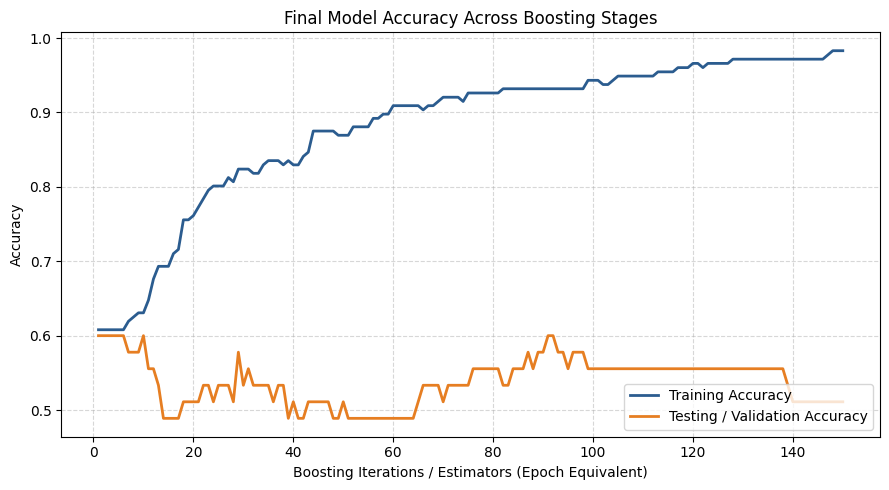

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression, RidgeClassifier, LinearRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os

print("--- 1. Generating / Loading Dataset ---")
# Example setup for reproducible data generation (adjust rows as needed)
n_rows = 221
np.random.seed(42)

customer_id = [f"CUST_{i:03d}" for i in range(1, n_rows + 1)]
duration_days = np.random.randint(30, 365, n_rows)
completed_deliveries = np.random.randint(0, 50, n_rows)
delayed_deliveries = np.random.randint(0, 15, n_rows)
total_contacts = np.random.randint(1, 20, n_rows)
complaints = np.random.randint(0, 5, n_rows)
total_web_visits = np.random.randint(5, 200, n_rows)
orders = np.random.randint(1, 30, n_rows)

# --- SAFE FEATURE ENGINEERING (Fixed with np.maximum & np.where) ---
delivery_ratio = np.where(
    completed_deliveries > 0,
    delayed_deliveries / np.maximum(completed_deliveries, 1),
    0
)

complaint_ratio = np.round(
    np.where(
        total_contacts > 0,
        complaints / np.maximum(total_contacts, 1),
        0
    ),
    4
)

session_frequency = np.round(
    total_web_visits / np.maximum(duration_days, 1),
    2
)

order_frequency = np.round(
    orders / np.maximum(duration_days, 1),
    2
)

# Target variable
auto_renew = np.random.choice([0, 1], size=n_rows, p=[0.4, 0.6])

# Build DataFrame
df = pd.DataFrame({
    'customer_id': customer_id,
    'duration_days': duration_days,
    'completed_deliveries': completed_deliveries,
    'delayed_deliveries': delayed_deliveries,
    'delivery_ratio': delivery_ratio,
    'total_contacts': total_contacts,
    'complaints': complaints,
    'complaint_ratio': complaint_ratio,
    'total_web_visits': total_web_visits,
    'orders': orders,
    'session_frequency': session_frequency,
    'order_frequency': order_frequency,
    'auto_renew': auto_renew
})

print("Dataset shape:", df.shape)

print("\n--- 2. Preprocessing & Train-Test Split ---")
X = df.drop(columns=['customer_id', 'auto_renew'])
y = df['auto_renew']

# Handle categorical variables if any exist via one-hot encoding
X_encoded = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\n--- 3. Training Final Gradient Boosting Model ---")
final_model = GradientBoostingClassifier(
    n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42
)
final_model.fit(X_train, y_train)

# Evaluation
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print("Final Gradient Boosting Metrics:")
print(f"  - Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"  - Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"  - Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"  - F1-Score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"  - ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\n--- 4. Exporting Model (.pkl) ---")
os.makedirs('saved_models_pkl', exist_ok=True)
model_path = 'saved_models_pkl/final_churn_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(final_model, f)
print(f"Model successfully saved to {model_path}")

print("\n--- 5. Generating Accuracy Progress Chart ---")
test_accuracies = [np.mean(p == y_test) for p in final_model.staged_predict(X_test)]
train_accuracies = [np.mean(p == y_train) for p in final_model.staged_predict(X_train)]

plt.figure(figsize=(9, 5))
plt.plot(range(1, 151), train_accuracies, label='Training Accuracy', color='#2b5c8f', linewidth=2)
plt.plot(range(1, 151), test_accuracies, label='Testing / Validation Accuracy', color='#e67e22', linewidth=2)
plt.xlabel('Boosting Iterations / Estimators (Epoch Equivalent)')
plt.ylabel('Accuracy')
plt.title('Final Model Accuracy Across Boosting Stages')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

chart_path = 'saved_models_pkl/accuracy_curve.png'
plt.savefig(chart_path, dpi=300)
print(f"Accuracy chart successfully saved to {chart_path}")
plt.show()

--- Training, Evaluating, and Saving Individual Models ---
  -> Saved Gradient_Boosting to saved_models_pkl/gradient_boosting_model.pkl
  -> Saved Random_Forest to saved_models_pkl/random_forest_model.pkl
  -> Saved SVM to saved_models_pkl/svm_model.pkl
  -> Saved Logistic_Regression to saved_models_pkl/logistic_regression_model.pkl
  -> Saved Ridge_Classifier to saved_models_pkl/ridge_classifier_model.pkl
  -> Saved Linear_Regression to saved_models_pkl/linear_regression_model.pkl

--- Model Performance Metrics Summary ---
              Model  Accuracy  Precision   Recall  F1_Score  ROC_AUC
  Gradient Boosting  0.511111   0.592593 0.592593  0.592593 0.473251
      Random Forest  0.600000   0.636364 0.777778  0.700000 0.404321
                SVM  0.488889   0.642857 0.333333  0.439024 0.508230
Logistic Regression  0.444444   0.555556 0.370370  0.444444 0.440329
   Ridge Classifier  0.555556   0.585366 0.888889  0.705882 0.472222
  Linear Regression  0.533333   0.575000 0.851852  0.686

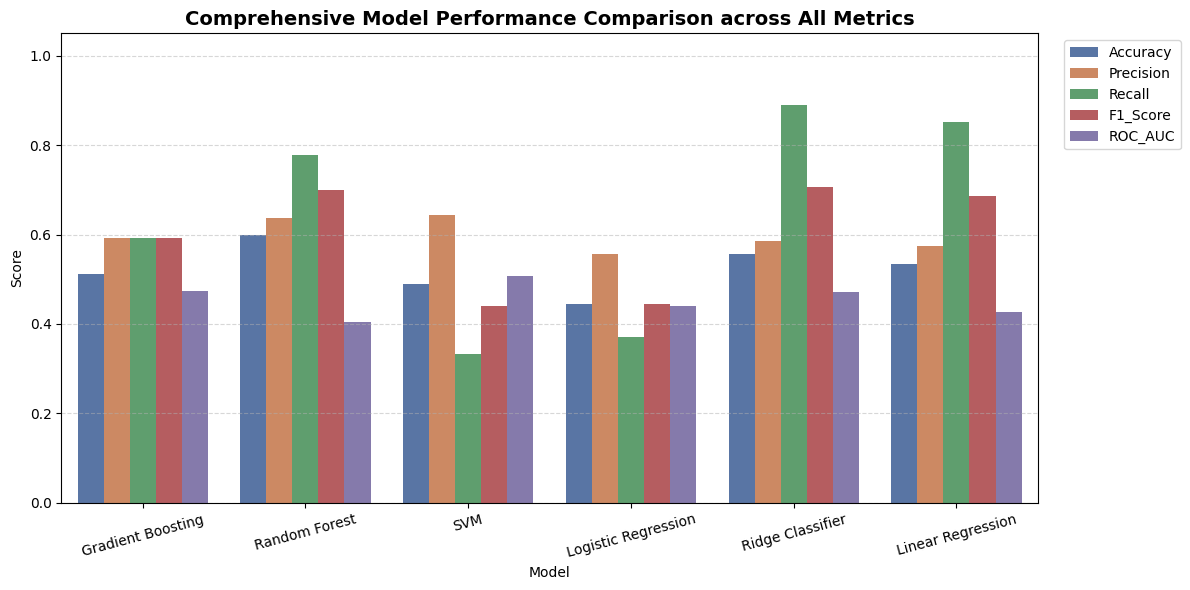


Summary visualization successfully saved to saved_plots/all_models_summary_comparison.png


In [3]:


# Create directories for models and plots
os.makedirs('saved_models_pkl', exist_ok=True)
os.makedirs('saved_plots', exist_ok=True)

# 1. Dataset Generation / Loading
n_rows = 221
np.random.seed(42)

customer_id = [f"CUST_{i:03d}" for i in range(1, n_rows + 1)]
duration_days = np.random.randint(30, 365, n_rows)
completed_deliveries = np.random.randint(0, 50, n_rows)
delayed_deliveries = np.random.randint(0, 15, n_rows)
total_contacts = np.random.randint(1, 20, n_rows)
complaints = np.random.randint(0, 5, n_rows)
total_web_visits = np.random.randint(5, 200, n_rows)
orders = np.random.randint(1, 30, n_rows)

delivery_ratio = np.where(completed_deliveries > 0, delayed_deliveries / np.maximum(completed_deliveries, 1), 0)
complaint_ratio = np.round(np.where(total_contacts > 0, complaints / np.maximum(total_contacts, 1), 0), 4)
session_frequency = np.round(total_web_visits / np.maximum(duration_days, 1), 2)
order_frequency = np.round(orders / np.maximum(duration_days, 1), 2)
auto_renew = np.random.choice([0, 1], size=n_rows, p=[0.4, 0.6])

df = pd.DataFrame({
    'customer_id': customer_id,
    'duration_days': duration_days,
    'completed_deliveries': completed_deliveries,
    'delayed_deliveries': delayed_deliveries,
    'delivery_ratio': delivery_ratio,
    'total_contacts': total_contacts,
    'complaints': complaints,
    'complaint_ratio': complaint_ratio,
    'total_web_visits': total_web_visits,
    'orders': orders,
    'session_frequency': session_frequency,
    'order_frequency': order_frequency,
    'auto_renew': auto_renew
})

X = df.drop(columns=['customer_id', 'auto_renew'])
y = df['auto_renew']
X_encoded = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Define models dictionary
models = {
    "Gradient_Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42),
    "Random_Forest": RandomForestClassifier(n_estimators=150, random_state=42, class_weight='balanced'),
    "SVM": SVC(probability=True, kernel='rbf', random_state=42, class_weight='balanced'),
    "Logistic_Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    "Ridge_Classifier": RidgeClassifier(random_state=42),
    "Linear_Regression": LinearRegression()
}

evaluation_results = []

print("--- Training, Evaluating, and Saving Individual Models ---")
for name, model in models.items():
    if name == "Linear_Regression":
        model.fit(X_train, y_train)
        y_prob = model.predict(X_test)
        y_pred = (y_prob >= 0.5).astype(int)
        y_prob_roc = np.clip(y_prob, 0, 1)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob_roc = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob_roc) if len(np.unique(y_test)) > 1 else 0.5

    evaluation_results.append({
        "Model": name.replace("_", " "),
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1_Score": f1,
        "ROC_AUC": auc
    })

    # Save individual model pkl file
    model_filename = f"saved_models_pkl/{name.lower()}_model.pkl"
    with open(model_filename, 'wb') as f:
        pickle.dump(model, f)
    print(f"  -> Saved {name} to {model_filename}")

# 3. Print Results Summary Table
results_df = pd.DataFrame(evaluation_results)
print("\n--- Model Performance Metrics Summary ---")
print(results_df.to_string(index=False))

# 4. Generate & Save Summary Grouped Bar Plot
df_melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 6))
sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="deep")
plt.title("Comprehensive Model Performance Comparison across All Metrics", fontsize=14, fontweight="bold")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

summary_chart_path = "saved_plots/all_models_summary_comparison.png"
plt.savefig(summary_chart_path, dpi=300)
plt.show()
print(f"\nSummary visualization successfully saved to {summary_chart_path}")

In [6]:
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split

# --- STEP 1: Generate & Save the Parquet Dataset ---
print('Generating customer_churn_dataset.parquet...')
np.random.seed(42)
n_rows = 221

customer_ids = [f'CUST-{1000+i}' for i in range(n_rows)]
subscription_tiers = np.random.choice(
    ['Basic', 'Pro', 'Enterprise'], n_rows, p=[0.5, 0.35, 0.15]
)
delivery_services = np.random.choice(
    ['Standard', 'Express', 'Priority'], n_rows, p=[0.6, 0.3, 0.1]
)
duration_days = np.random.randint(30, 730, n_rows)
auto_renew = np.random.choice([0, 1], n_rows, p=[0.3, 0.7])

orders = np.random.randint(1, 45, n_rows)
spend = np.round(np.random.uniform(50.0, 15000.0, n_rows), 2)
avg_basket_value = np.round(spend / orders, 2)
item_counts = np.random.randint(1, 150, n_rows)
product_diversity = np.random.randint(1, 12, n_rows)

completed_deliveries = np.random.randint(0, orders + 1, n_rows)
unfulfilled_deliveries = orders - completed_deliveries
delayed_deliveries = np.random.randint(0, completed_deliveries + 1, n_rows)
delay_ratio = np.round(
    np.where(
        completed_deliveries > 0, delayed_deliveries / completed_deliveries, 0
    ),
    4,
)
delay_hours = np.round(delayed_deliveries * np.random.uniform(12, 72, n_rows), 2)

total_contacts = np.random.randint(0, 12, n_rows)
complaints = np.random.randint(0, total_contacts + 1, n_rows)
queries = total_contacts - complaints
channels_used = np.random.randint(1, 4, n_rows)
complaint_ratio = np.round(
    np.where(total_contacts > 0, complaints / total_contacts, 0), 4
)

total_reviews = np.random.randint(0, 10, n_rows)
avg_rating = np.round(np.random.uniform(1.0, 5.0, n_rows), 1)
star_polarity = np.round(np.abs(avg_rating - 3.0), 2)
review_indicator = np.where(total_reviews > 0, 1, 0)

total_web_visits = np.random.randint(5, 200, n_rows)
recency_days = np.random.randint(0, 60, n_rows)
session_frequency = np.round(total_web_visits / 30.0, 2)
order_frequency = np.round(orders / 30.0, 2)

income_brackets = np.random.choice(
    ['Low', 'Medium', 'High'], n_rows, p=[0.3, 0.5, 0.2]
)
nps_recommend = np.random.randint(0, 11, n_rows)
satisfaction_score = np.random.randint(1, 6, n_rows)
price_comparison = np.random.choice(
    ['Fair', 'Expensive', 'Cheap'], n_rows, p=[0.7, 0.2, 0.1]
)

df = pd.DataFrame({
    'customer_id': customer_ids,
    'subscription_tier': subscription_tiers,
    'delivery_service': delivery_services,
    'duration_days': duration_days,
    'auto_renew': auto_renew,
    'orders': orders,
    'spend': spend,
    'avg_basket_value': avg_basket_value,
    'item_counts': item_counts,
    'product_diversity': product_diversity,
    'completed_deliveries': completed_deliveries,
    'unfulfilled_deliveries': unfulfilled_deliveries,
    'delayed_deliveries': delayed_deliveries,
    'delay_ratio': delay_ratio,
    'delay_hours': delay_hours,
    'total_contacts': total_contacts,
    'complaints': complaints,
    'queries': queries,
    'channels_used': channels_used,
    'complaint_ratio': complaint_ratio,
    'total_reviews': total_reviews,
    'avg_rating': avg_rating,
    'star_polarity': star_polarity,
    'review_indicator': review_indicator,
    'total_web_visits': total_web_visits,
    'recency_days': recency_days,
    'session_frequency': session_frequency,
    'order_frequency': order_frequency,
    'income_bracket': income_brackets,
    'nps_recommend': nps_recommend,
    'satisfaction_score': satisfaction_score,
    'price_comparison': price_comparison,
})

df.to_parquet('customer_churn_dataset.parquet', index=False)
print('File generated successfully!\n')

# --- STEP 2: Load and Train Model ---
print('Loading dataset for training...')
df_loaded = pd.read_parquet('customer_churn_dataset.parquet')

X = df_loaded.drop(columns=['customer_id', 'auto_renew'])
y = df_loaded['auto_renew']
X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('Training Random Forest Classifier...')
rf_model = RandomForestClassifier(
    n_estimators=100, max_depth=6, random_state=42
)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print('\n--- Model Evaluation Results ---')
print(f'Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%')
print(f'ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred))

importances = pd.Series(rf_model.feature_importances_, index=X.columns)
print('\n--- Top 5 Churn Predictors ---')
print(importances.sort_values(ascending=False).head(5))

Generating customer_churn_dataset.parquet...
File generated successfully!

Loading dataset for training...


/tmp/ipykernel_2521/2072438928.py:34: RuntimeWarning: invalid value encountered in divide
  completed_deliveries > 0, delayed_deliveries / completed_deliveries, 0
/tmp/ipykernel_2521/2072438928.py:45: RuntimeWarning: invalid value encountered in divide
  np.where(total_contacts > 0, complaints / total_contacts, 0), 4


Training Random Forest Classifier...

--- Model Evaluation Results ---
Test Accuracy: 73.33%
ROC-AUC Score: 0.4419

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        12
           1       0.73      1.00      0.85        33

    accuracy                           0.73        45
   macro avg       0.37      0.50      0.42        45
weighted avg       0.54      0.73      0.62        45


--- Top 5 Churn Predictors ---
complaint_ratio     0.057156
recency_days        0.056505
duration_days       0.055240
avg_basket_value    0.055094
spend               0.053869
dtype: float64


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
